# The exponential distribution

- [Probability density function](#probability-density-function)
- [Cumulative distribution function](#cumulative-distribution-function)
- [Minimum of exponential distributed random variables](#minimum-of-exponential-distributed-random-variables)
- [Moment generating function](#moment-generating-function)
- [Expected value and variance](#expected-value-and-variance)
- [Sum of exponentially distributed random variables](#sum-of-exponentially-distributed-random-variables)
- [Simulation](#simulation)

## Probability density function

For $\lambda>0$ the *exponential distribution* is given by the probability density function
$$f(x):= \lambda e^{-\lambda x} I_{[0,\infty)}(x).$$

The parameter $\lambda$ is called the rate, $1/\lambda$ the scale. 
We denote $X\sim \exp(rate=\lambda)$. 
The pdf (probability density function) can be found in 
`
scipy.stats.expon.pdf(x, scale=1/rate)
`. 


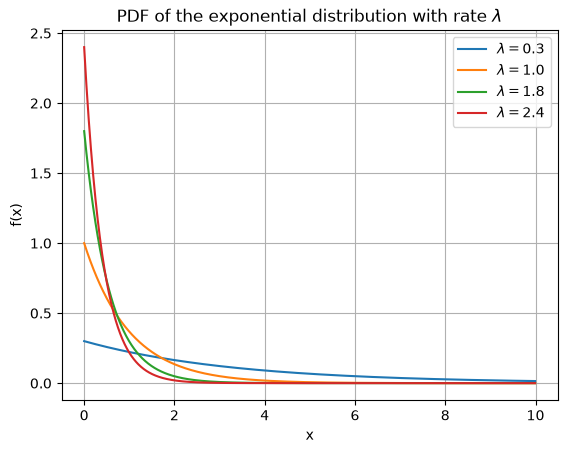

In [1410]:
from matplotlib import pyplot as plt
from math import exp
import numpy as np

rate_choices = [0.3, 1.0, 1.8, 2.4]

def exponential_distribution_pdf(rate=1): 
    return lambda x : rate*exp(-rate*x) if x>=0 else 0

x_min = 0
x_max = 10
step = 0.01

range_x = np.arange(x_min,x_max, step)

for rate in rate_choices:
    f = exponential_distribution_pdf(rate=rate)
    plt.plot(range_x, [f(x) for x in range_x], label=fr'$\lambda = {rate}$')
plt.xlabel("x")
plt.ylabel("f(x)")
plt.title(rf"PDF of the exponential distribution with rate $\lambda$")
plt.grid()
plt.legend()
plt.show()

## Cumulative distribution function

**Proposition:**
For $X\sim \exp(rate=\lambda)$ the cumulative distribution function of $X$ is given by 
$$F_X(x)=(1-e^{-\lambda x})I_{[0,\infty)}(x).$$

*Proof:*
The statement is clear for $x\leq 0$. For $x>0$ we compute
$$
    F_X(x)
    =P(X\leq x)
    = \int_0^x \lambda e^{-\lambda x} dx
    = \frac{\lambda}{-\lambda}\left[e^{-\lambda x}\right]_0^x
    = 1-e^{-\lambda x}. 
    \qquad \blacksquare
    $$

The cdf (cumulative density function) of the exponential distribution can be found as 
`
scipy.stats.expon.cdf(x, scale=1/2)
`, where the scale is the inverse of the rate. 

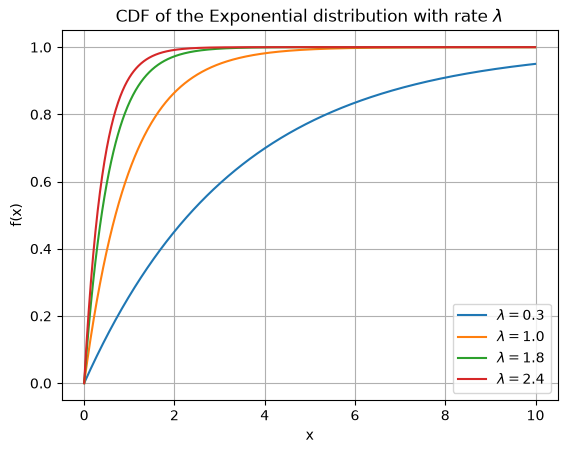

In [1411]:
from matplotlib import pyplot as plt
from math import exp
import numpy as np
import scipy

rate_choices = [0.3, 1.0, 1.8, 2.4]
x_min, x_max, step = 0, 10, 0.01
range_x = np.arange(x_min,x_max, step)

for rate in rate_choices:
    F = lambda x : 1-exp(-rate*x) if x>=0 else 0        #F = lambda x: scipy.stats.expon.cdf(x, scale=1/rate)
    plt.plot(range_x, [F(x) for x in range_x], label=fr'$\lambda = {rate}$')
plt.xlabel("x")
plt.ylabel("f(x)")
plt.title(rf"CDF of the Exponential distribution with rate $\lambda$")
plt.grid()
plt.legend()
plt.show()

## Minimum of exponential distributed random variables

**Proposition:**
If $X_1,\dots, X_n$ are independent and exponential distributed random variables with rates $\lambda_i$, then $\min (X_1,\dots,X_n)$ is exponential distributed with rate $\sum_{i=1}^n\lambda_i$. 

*Proof:*
For $Y:=\min (X_1,\dots,X_n) $ and $x>0$ we have 
\begin{align*}
    F_Y(x)
    &= 1-P(Y>x)\\
    &= 1-P(X_1>x,\dots,X_n>x)\\
    &\overset{ind.}{=} 1-\prod_{i=1}^n P(X_i>x)\\
    &= 1-\prod_{i=1}^n e^{-\lambda_i x}
    = 1-e^{-(\sum_{i=1}^n\lambda_i) x}
    \qquad \blacksquare
\end{align*}

A little experiment for illustration:

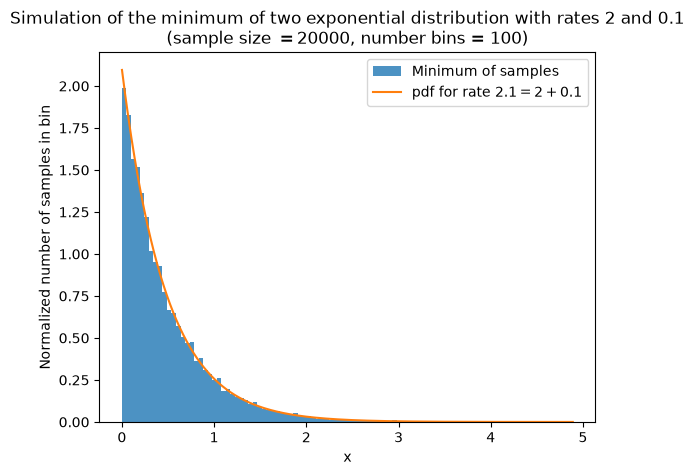

In [1412]:
import numpy as np

lambda_1 = 2
lambda_2 = 0.1
lambda_sum = lambda_1+lambda_2

# SAMPLING
sample_size = 20000
# Simulate samples from the respective exponential distributions
samples_1 = np.random.exponential(scale=1/lambda_1, size=sample_size)
samples_2 = np.random.exponential(scale=1/lambda_2, size=sample_size)
# Compute the pairwise minimum
samples_min = np.minimum(samples_1,samples_2)

# VISUALIZATOIN
number_bins, step = 100, 0.001
x_range = np.arange(step, max(samples_min), step)
plt.hist(samples_min, bins = number_bins, density= True, alpha=0.8, label = rf"Minimum of samples")
f = lambda x : scipy.stats.expon.pdf(x, scale=1/lambda_sum)
plt.plot(x_range, f(x_range), label=rf"pdf for rate ${lambda_sum}={lambda_1}+{lambda_2}$")
plt.title(rf'Simulation of the minimum of two exponential distribution with rates {lambda_1} and {lambda_2}'+'\n'+rf'(sample size $= {sample_size}$, number bins = {number_bins})')
plt.xlabel('x')
plt.ylabel('Normalized number of samples in bin')
plt.legend()
plt.show()


## Memorylessness characterization

A absolutely continuous random varianble is called *memoryless* if it satisfies 
$$
P(X>s+t \mid X>s)=P(X>t)
$$ 
for all $s,t>0$ (for which $P(X>s)>0$). 

**Theorem:**
Let $X$ be a nonnegative, absolutely continuous random variable satisfying $P(X>0)=1$.

Then $X$ is memoryless if and only if there exists a parameter $\lambda>0$ such that
$X\sim\operatorname{Exp}(\lambda).$ 
In the latter case the rate is given by $\lambda = -\log(P(X>1))$. 

*Proof:*
To see that every exponential distribution is memoryless assume that $X\sim\operatorname{Exp}(\lambda)$, where $\lambda>0$. We have already computed the cdf. Thus, its survival function is given by
$
S(t)=P(X>t)=e^{-\lambda t}I_{(0,\infty)}(x).
$
For arbitrary $s,t>0$, we obtain
\begin{align*}
    P(X>s+t\mid X>s)
    =\frac{P(X>s+t)}{P(X>s)}
    =\frac{e^{-\lambda(s+t)}}{e^{-\lambda s}}
    =e^{-\lambda t}
    =P(X>t),
\end{align*}
which shows that $X$ is memoryless. For the converse suppose that $X$ is memoryless.
Let $S(t):=P(X>t)$ denote its survival function and $\lambda:=-\log(S(1))$. 
By the definition of memorylessness we have 
$S(s+t)=S(s)S(t)$. 
For natural numbers $n$ and $m$ we thus have 
\begin{align*}
    S(n/m)^m
    =S(n/m+\dots +n/m)
    =S(mn/m)
    =S(n)
    =S(1+\dots+1)
    =S(1)^n
\end{align*}
and hence $S(q)=S(1)^q$ for all rational numbers $q>0$. Since $S$ is continuous we observe $S(x)=S(1)^x=(e^{-\lambda})^x=e^{-\lambda x}$ for all real $x>0$, i.e. that 
$X\sim \exp(rate= \lambda)$. $\qquad \blacksquare$

A little simulation shall illustrate the memorylessness. 

10000000 150324


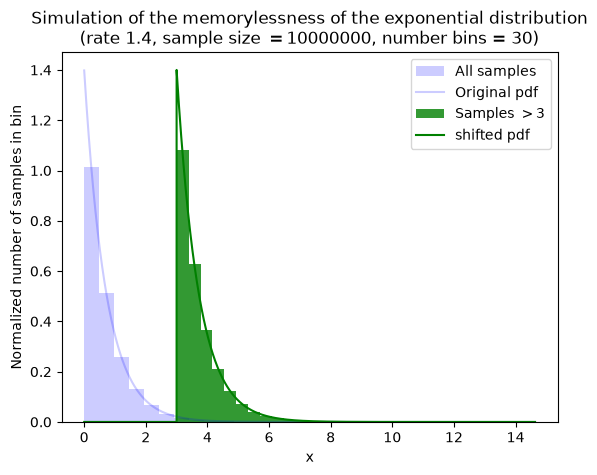

In [ ]:
import numpy as np

rate = 1.4
s=3

# SAMPLING
sample_size = 10000000
# Simulate samples from the respective exponential distributions
samples = np.random.exponential(scale=1/rate, size=sample_size)

# Filter out all values that are smaller than s
samples_1 = samples[samples > s]

print(len(samples), len(samples_1))

# VISUALIZATOIN
number_bins, step = 30, 0.001
x_range = np.arange(step, max(samples), step)
plt.hist(samples, bins = number_bins, density= True, alpha=0.2, label = rf"All samples", color = "blue")
plt.plot(x_range, scipy.stats.expon.pdf(x_range, scale=1/rate), label=rf"Original pdf", color = "blue", alpha = 0.2)
plt.hist(samples_1, bins = number_bins, density= True, alpha=0.8, label = rf"Samples $> {s}$", color = "green")
plt.plot(x_range, scipy.stats.expon.pdf(x_range-s, scale=1/rate), label=rf"shifted pdf", color = "green")
plt.title(rf'Simulation of the memorylessness of the exponential distribution'+'\n'+rf'(rate ${rate}$, sample size $= {sample_size}$, number bins = {number_bins})')
plt.xlabel('x')
plt.ylabel('Normalized number of samples in bin')
plt.legend()
plt.show()





## Moment generating function

**Lemma:**
For $X\sim \exp(rate=\lambda)$ the moment generating function of $X$ is given by 
$$
M_X(t)=\frac{\lambda}{\lambda -t}
$$ 
as long as $t<\lambda$. 

*Proof:*
For $t<\lambda$ we have $e^{(t-\lambda)x}\to 0 $ as $x\to \infty$ and hence
\begin{align*}
    M_X(t)
    &=\mathbb{E}[e^{tX}]
    =\int_{0}^\infty e^{tx}\lambda e^{-\lambda x} dx
    = \lambda \int_{0}^\infty e^{(t-\lambda)x} dx\\
    &= \lambda \left[\frac{1}{t-\lambda}e^{(t-\lambda)x}\right]_0^\infty
    =\frac{\lambda}{t-\lambda}(0-1)
    =\frac{\lambda}{\lambda-t}.
    \qquad \blacksquare
\end{align*}

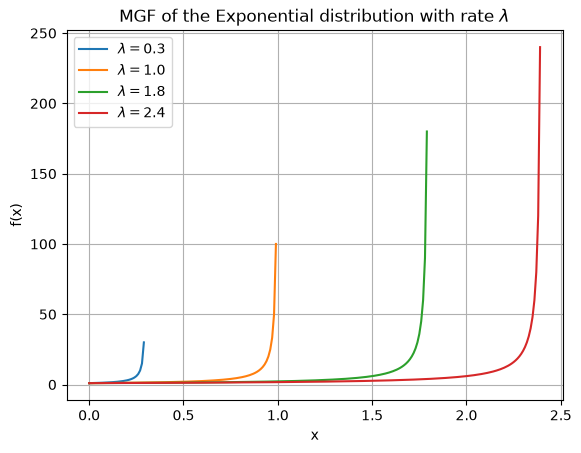

In [1414]:
from matplotlib import pyplot as plt
from math import exp
import numpy as np
import scipy

rate_choices = [0.3, 1.0, 1.8, 2.4]
x_min, x_max, step = 0, 10, 0.01
range_x = np.arange(x_min,x_max, step)

for rate in rate_choices:
    M = lambda t : rate/(rate-t) if t<rate else np.nan        #F = lambda x: scipy.stats.expon.cdf(x, scale=1/rate)
    plt.plot(range_x, [M(x) for x in range_x], label=fr'$\lambda = {rate}$')
plt.xlabel("x")
plt.ylabel("f(x)")
plt.title(rf"MGF of the Exponential distribution with rate $\lambda$")
plt.grid()
plt.legend()
plt.show()

## Expected value and variance

**Proposition:** For $X\sim \exp(rate=\lambda)$ we have $\mathbb{E}[X]=\frac{1}{\lambda}$ and $\operatorname{Var}[X]=\frac{1}{\lambda^2}$. 

*Proof:*
We compute 
$$
M_X'(t)
=\frac{-\lambda(-1)}{(\lambda-t)^2}
=\frac{\lambda}{(\lambda-t)^2}
$$
and deduce $\mathbb{E}[X]=\lambda/(\lambda-0)^2=1/\lambda$. 
Furthermore, 
$$
\mathbb{E}[X^2]
=M_X''(0)
=-\lambda\frac{2(\lambda-0)(-1)}{(\lambda-0)^4}
=\frac{2\lambda^2}{\lambda^4}
=\frac{2}{\lambda^2}. 
$$
Thus, 
\begin{align*}
    \operatorname{Var}[X]
    =\mathbb{E}[X^2]-\mathbb{E}[X]^2
    =\frac{2}{\lambda^2}-\frac{1}{\lambda^2}
    =\frac{1}{\lambda^2}.
    \qquad \blacksquare
\end{align*}


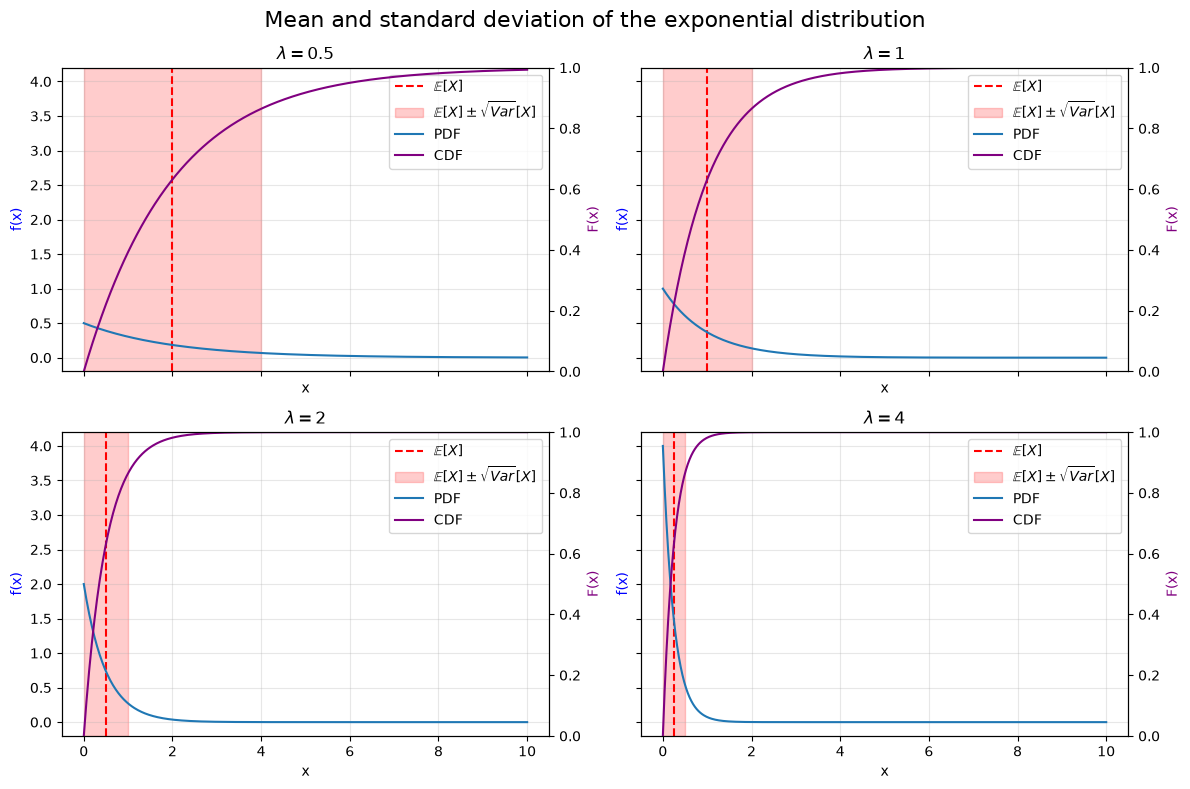

In [1415]:
from matplotlib import pyplot as plt
from math import sqrt
import numpy as np
import scipy

rates = [0.5, 1, 2, 4]
x_min, x_max = 0, 10
steps = 500

x_range = np.linspace(x_min, x_max, steps)
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True, sharey=True)
for ax, rate in zip(axes.flat, rates):
    mean = 1/rate
    variance = 1/(rate**2)
    std = sqrt(variance)
    # Mean
    mean_label = rf'$\mathbb{{E}}[X]$'
    ax.axvline(x=mean, color='red', linestyle='--', label=mean_label)
    # STD
    std_label = rf'$\mathbb{{E}}[X]\pm\sqrt{{Var}}[X]$'
    ax.axvspan(mean-std, mean+std, color='red', alpha=0.2, label=std_label)
    # PDF
    ax.plot(x_range, scipy.stats.expon.pdf(x_range, scale=1/rate), label="PDF")
    ax.set_xlabel("x")
    ax.set_ylabel("f(x)", color="blue")
    ax.set_title(fr"$\lambda = {rate}$")
    ax.grid(alpha=0.3)
    # CDF
    ax2 = ax.twinx()
    ax2.plot(x_range, scipy.stats.expon.cdf(x_range, scale=1/rate), color='purple', linestyle='-', label="CDF")
    ax2.set_ylabel("F(x)", color="purple")
    ax2.set_ylim(0, 1)
    # Combined legend
    lines1, labels1 = ax.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()
    ax.legend(lines1 + lines2, labels1 + labels2)
fig.suptitle("Mean and standard deviation of the exponential distribution", fontsize=16)
plt.tight_layout()
plt.show()


## Sum of exponentially distributed random variables

**Proposition:** 
If $X_1,\dots,X_n$ are iid and exponential distributed with rate $\lambda$, 
then $\sum_{i=1}^n X_i \sim \Gamma(n,\lambda)$, i.e.\ the sum of iid exponential distributed random varianbles is gamma distributed with the same rate and shape parameter being the number of random variables being summed.

*Proof:* 
Using the independence we compute for $X:=\sum_{i=1}^n X_i$ that
$$
M_X(t)
=\mathbb{E}[e^{tX}]
=\mathbb{E}[\prod_{i=1}^n e^{tX_i}]
\overset{ind.}{=}\prod_{i=1}^n \mathbb{E}[e^{tX_i}]
=\prod_{i=1}^n \left(\frac{\lambda}{t-\lambda}\right)
=\left(\frac{\lambda}{t-\lambda}\right)^n
$$
the latter is known to be the moment generating function of a gamma distribution. 
$\qquad \blacksquare$

Note that for integer shape parameters the gamma distribution is also called *Erlang distribution*. 
A little experiment for illustration follows. Note that the pdf of the gamma distribution can be visualized from `scipy.stats.gamma.pdf(x, a=n, scale=1/rate)`, where the scale is once more the inverse of the rate. 


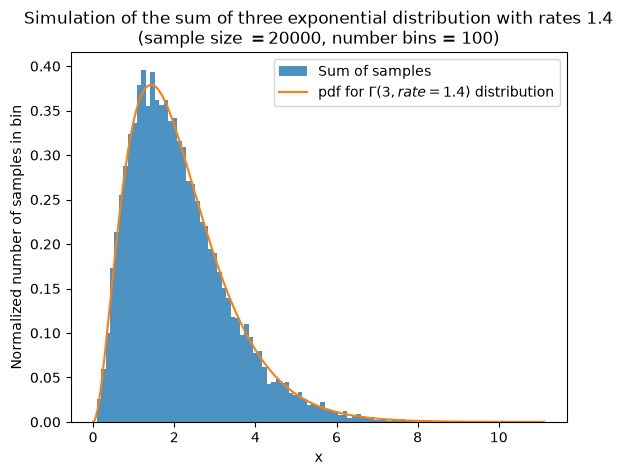

In [1416]:
import numpy as np

rate_individual = 1.4

# SAMPLING
sample_size = 20000
# Simulate samples from the respective exponential distributions
samples_1 = np.random.exponential(scale=1/rate_individual, size=sample_size)
samples_2 = np.random.exponential(scale=1/rate_individual, size=sample_size)
samples_3 = np.random.exponential(scale=1/rate_individual, size=sample_size)
# Compute the pairwise sum
samples_sum = samples_1 + samples_2 + samples_3

# VISUALIZATOIN
number_bins, step = 100, 0.001
x_range = np.arange(step, max(samples_sum), step)
plt.hist(samples_sum, bins = number_bins, density= True, alpha=0.8, label = rf"Sum of samples")
plt.plot(x_range, scipy.stats.gamma.pdf(x_range, a=3, scale=1/rate_individual), label=rf"pdf for $\Gamma(3,rate={rate_individual})$ distribution")
plt.title(rf'Simulation of the sum of three exponential distribution with rates {rate_individual}'+'\n'+rf'(sample size $= {sample_size}$, number bins = {number_bins})')
plt.xlabel('x')
plt.ylabel('Normalized number of samples in bin')
plt.legend()
plt.show()


## Simulation

The exponential distribution can easily be simulated via the modules `random`, `numpy` or `scipy`. 

0.12712626973287475


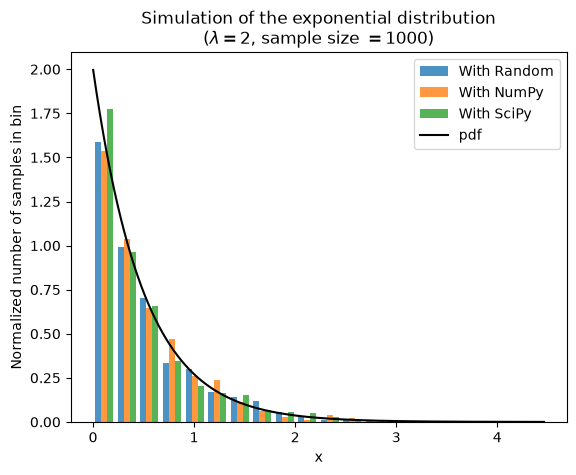

In [1417]:
import random, scipy

rate = 2  # Rate parameter

# A single sample:
x = random.expovariate(rate)
print(x)

# A whole sample:
sample_size = 1000
label_1 = "With Random"
samples_1 = [random.expovariate(rate) for _ in range(sample_size)]

label_2 = "With NumPy"
samples_2 = np.random.exponential(
    scale=1/rate, 
    size=sample_size
)

label_3 = "With SciPy"
samples_3 = samples = scipy.stats.expon.rvs(
    scale=1/rate,
    size=sample_size#,
    #random_state=42
)

# Visualization of the samples
number_bins = 20

plt.hist(
    [samples_1, samples_2, samples_3],
    bins=number_bins,
    density=True,
    label=[label_1, label_2, label_3],
    histtype="bar",
    alpha=0.8
)

#plt.hist(samples, bins = number_bins, density= True, alpha=0.6)

step = 0.001
maximum = max(max(samples_1),max(samples_2),max(samples_3))
x_range = np.arange(step, maximum, step)
f = lambda x : scipy.stats.expon.pdf(x, scale=1/rate)
plt.plot(x_range, f(x_range), label="pdf", color = "black")

plt.title('Simulation of the exponential distribution\n'+rf'($\lambda={rate}$, sample size $= {sample_size}$)')
plt.xlabel('x')
plt.ylabel('Normalized number of samples in bin')
plt.legend()
plt.show()